In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # En Jupyter local no es necesario montar Drive.

posibles_rutas = [
    Path('/content/drive/MyDrive/mineriaDatos/online_shoppers_intention.csv'),
    Path('online_shoppers_intention.csv'),
    Path('/mnt/data/online_shoppers_intention.csv'),
]
archivo = next((p for p in posibles_rutas if p.exists()), None)
if archivo is None:
    raise FileNotFoundError('Coloca online_shoppers_intention.csv en la carpeta mineriaDatos de Drive o junto al notebook.')

df = pd.read_csv(archivo)
df_original = df.copy()
print('Archivo:', archivo)
print('Dimensiones originales:', df_original.shape)
display(df_original.head())

Mounted at /content/drive
Archivo: /content/drive/MyDrive/mineriaDatos/online_shoppers_intention.csv
Dimensiones originales: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


###  Comprobar faltantes y duplicados

**este dataset no tiene valores faltantes**. Por ello no aplicaremos `fillna()` sin necesidad. Es importante no alterar datos correctos.

In [3]:
faltantes = pd.DataFrame({
    'Cantidad': df_original.isna().sum(),
    'Porcentaje': (df_original.isna().mean() * 100).round(2)
})
print('Valores faltantes totales:', int(df_original.isna().sum().sum()))
display(faltantes)

print('Filas duplicadas adicionales:', int(df_original.duplicated().sum()))
print('Filas involucradas en grupos duplicados:', int(df_original.duplicated(keep=False).sum()))
print('Revenue de los duplicados adicionales:')
print(df_original.loc[df_original.duplicated(), 'Revenue'].value_counts())

Valores faltantes totales: 0


,Cantidad,Porcentaje
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Filas duplicadas adicionales: 125
Filas involucradas en grupos duplicados: 201
Revenue de los duplicados adicionales:
Revenue
False    125
Name: count, dtype: int64


### Crear una versión sin duplicados

En el dataset no existe un identificador único de sesión. Dos sesiones distintas podrían tener los mismos valores. Por eso conservamos dos versiones:

- `df_original`: todas las sesiones del CSV (sin modificar).
- `df_sin_duplicados`: se conserva la primera aparición de cada fila y se elimina el resto.

**Decisión inicial para los modelos:** usar la versión sin duplicados, para evitar que copias idénticas de una fila puedan quedar en entrenamiento y prueba. Más adelante comprobaremos si conservarlas cambia los resultados; no podemos asegurar que todas sean errores de captura.

In [4]:
df_sin_duplicados = df_original.drop_duplicates(keep='first').reset_index(drop=True)

comparacion = pd.DataFrame({
    'Dataset': ['Original', 'Sin duplicados'],
    'Sesiones': [len(df_original), len(df_sin_duplicados)],
    'Compras': [int(df_original['Revenue'].sum()), int(df_sin_duplicados['Revenue'].sum())],
    'Porcentaje de compra': [df_original['Revenue'].mean() * 100,
                             df_sin_duplicados['Revenue'].mean() * 100]
})
display(comparacion.round(2))

# Cambiar a False solo cuando hagamos la comparación de sensibilidad.
ELIMINAR_DUPLICADOS = True

df_trabajo = (df_sin_duplicados.copy() if ELIMINAR_DUPLICADOS
              else df_original.copy())
print('Dataset elegido para los siguientes pasos:', df_trabajo.shape)

,Dataset,Sesiones,Compras,Porcentaje de compra
0,Original,12330,1908,15.47
1,Sin duplicados,12205,1908,15.63


Dataset elegido para los siguientes pasos: (12205, 18)


**Exclusión de variables con posible fuga de información**

**Observaciones:**

- Se decidió excluir `PageValues` de los modelos de clasificación y regresión como medida preventiva ante una posible fuga de información.
- Esta variable contiene información relacionada con el valor de las páginas visitadas y las transacciones comerciales. Dependiendo del momento en que se calcule, podría contener información no disponible al realizar la predicción.
- Mantenerla podría generar resultados demasiado optimistas y dificultar la evaluación del desempeño real de los modelos.
- Por esta razón, se conserva para el análisis exploratorio, pero no se utiliza como variable predictora en los modelos supervisados.

###  Verificar tipos de variables y categorías

Aunque `OperatingSystems`, `Browser`, `Region` y `TrafficType` están guardadas como enteros, son **códigos categóricos**. `SpecialDay` es una escala numérica de proximidad a una fecha especial; no la convertimos en etiqueta.

In [6]:
variables_numericas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

variables_categoricas = [
    'Month', 'OperatingSystems', 'Browser', 'Region',
    'TrafficType', 'VisitorType', 'Weekend', 'Revenue'
]

for variable in variables_categoricas:
    print(f'{variable}: {df_trabajo[variable].nunique()} categorías')
    print(df_trabajo[variable].value_counts().head(10))
    print('-' * 35)

Month: 10 categorías
Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64
-----------------------------------
OperatingSystems: 8 categorías
OperatingSystems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64
-----------------------------------
Browser: 13 categorías
Browser
2     7883
1     2427
4      731
5      465
6      174
10     163
8      135
3      105
13      56
7       49
Name: count, dtype: int64
-----------------------------------
Region: 9 categorías
Region
1    4714
3    2379
4    1171
2    1128
6     801
7     758
9     505
8     431
5     318
Name: count, dtype: int64
-----------------------------------
TrafficType: 20 categorías
TrafficType
2     3911
1     2388
3     2013
4     1066
13     728
10     450
6      443
8      343
5      260
11     247
Name: count, dtype: int64
---------------------------------

### Revisar valores fuera de rangos posibles

Para detectar errores básicos, revisamos si hay conteos, duraciones y valores negativos o tasas fuera de sus rangos admitidos.

In [7]:
columnas_no_negativas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration', 'PageValues'
]

for variable in columnas_no_negativas:
    print(variable, '- valores negativos:', int((df_trabajo[variable] < 0).sum()))

for variable in ['BounceRates', 'ExitRates', 'SpecialDay']:
    fuera_de_rango = ~df_trabajo[variable].between(0, 1)
    print(variable, '- fuera de [0,1]:', int(fuera_de_rango.sum()))

Administrative - valores negativos: 0
Administrative_Duration - valores negativos: 0
Informational - valores negativos: 0
Informational_Duration - valores negativos: 0
ProductRelated - valores negativos: 0
ProductRelated_Duration - valores negativos: 0
PageValues - valores negativos: 0
BounceRates - fuera de [0,1]: 0
ExitRates - fuera de [0,1]: 0
SpecialDay - fuera de [0,1]: 0


###  Detectar posibles valores atipicos mediante el IQR


Cuando el IQR vale cero, un valor positivo podría aparecer marcado como atípico aunque sea completamente válido. No eliminamos ni recortamos automáticamente estas observaciones.

In [8]:
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara = (serie < limite_inferior) | (serie > limite_superior)
    return mascara, limite_inferior, limite_superior, iqr

filas_outliers = []
for variable in variables_numericas:
    mascara, li, ls, iqr = detectar_outliers_iqr(df_trabajo[variable])
    filas_outliers.append({
        'Variable': variable,
        'IQR': iqr,
        'Límite inferior': li,
        'Límite superior': ls,
        'Posibles outliers': int(mascara.sum()),
        'Porcentaje': 100 * mascara.mean()
    })

tabla_outliers = pd.DataFrame(filas_outliers)
display(tabla_outliers.round(2))

,Variable,IQR,Límite inferior,Límite superior,Posibles outliers,Porcentaje
0,Administrative,4.00,-6.00,10.00,404,3.31
1,Administrative_Duration,94.70,-142.05,236.75,1149,9.41
2,Informational,0.00,0.00,0.00,2631,21.56
3,Informational_Duration,0.00,0.00,0.00,2405,19.71
4,ProductRelated,30.00,-37.00,83.00,1007,8.25
5,ProductRelated_Duration,1284.15,-1733.23,3403.39,951,7.79
6,BounceRates,0.02,-0.03,0.04,1428,11.70
7,ExitRates,0.03,-0.04,0.10,1325,10.86
8,PageValues,0.00,0.00,0.00,2730,22.37
9,SpecialDay,0.00,0.00,0.00,1249,10.23


###  Revisar la consistencia del texto

Comprobamos las etiquetas de mes y tipo de visitante.

In [9]:
for variable in ['Month', 'VisitorType']:
    print(f'Valores únicos de {variable}:')
    print(sorted(df_trabajo[variable].unique()))
    print()

# Conservar los valores originales: no se encontraron nulos ni nombres
# alternativos demostrados para estas dos columnas.

Valores únicos de Month:
['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']

Valores únicos de VisitorType:
['New_Visitor', 'Other', 'Returning_Visitor']



###  Variables nuevas para describir navegación
Para **este** dataset de comercio electrónico, una alternativa coherente es contar el total de páginas visitadas y si hubo consultas informativas. No se añadirán automáticamente como predictores hasta decidir si son útiles.

In [29]:
# Crear nuevas variables relacionadas con la navegación

# Total de páginas visitadas
df_trabajo['PaginasTotales'] = (
    df_trabajo['Administrative']
    + df_trabajo['Informational']
    + df_trabajo['ProductRelated']
)

# Identificar si se visitaron páginas informativas (1 = Sí, 0 = No)
df_trabajo['VisitoInformativas'] = (
    df_trabajo['Informational'] > 0
).astype(int)

# Tiempo promedio dedicado a cada página de productos (segundos)
df_trabajo['TiempoPromedioProducto'] = (
    df_trabajo['ProductRelated_Duration']
    / df_trabajo['ProductRelated'].replace(0, np.nan)
).fillna(0)

# Proporción de páginas visitadas que corresponden a productos
df_trabajo['PorcentajePaginasProducto'] = (
    df_trabajo['ProductRelated']
    / df_trabajo['PaginasTotales'].replace(0, np.nan)
).fillna(0)

# Tiempo promedio registrado por página visitada (segundos)
df_trabajo['TiempoPromedioPagina'] = (
    (
        df_trabajo['Administrative_Duration']
        + df_trabajo['Informational_Duration']
        + df_trabajo['ProductRelated_Duration']
    )
    / df_trabajo['PaginasTotales'].replace(0, np.nan)
).fillna(0)

# Mostrar las variables creadas
variables_nuevas = [
    'PaginasTotales',
    'VisitoInformativas',
    'TiempoPromedioProducto',
    'PorcentajePaginasProducto',
    'TiempoPromedioPagina'
]

display(df_trabajo[variables_nuevas].head())

,PaginasTotales,VisitoInformativas,TiempoPromedioProducto,PorcentajePaginasProducto,TiempoPromedioPagina
0,1,0,0.000000,1.0,0.000000
1,2,0,32.000000,1.0,32.000000
2,1,0,0.000000,1.0,0.000000
3,2,0,1.333333,1.0,1.333333
4,10,0,62.750000,1.0,62.750000


**Observaciones:**

- Se generaron cinco variables derivadas para representar diferentes características del comportamiento de navegación.
- **`PaginasTotales`** representa la suma de páginas administrativas, informativas y de productos consultadas durante la sesión.
- **`VisitoInformativas`** indica si se consultó al menos una página informativa, utilizando 1 para sí y 0 para no.
- **`TiempoPromedioProducto`** representa el tiempo promedio dedicado a cada página de productos consultada, en segundos.
- **`PorcentajePaginasProducto`** representa la proporción de páginas consultadas que corresponden a productos. Sus valores están entre 0 y 1.
- **`TiempoPromedioPagina`** representa el tiempo promedio registrado por página, considerando las tres secciones del sitio, en segundos.
- Para evitar divisiones entre cero, se asignó el valor 0 cuando no se registraron páginas en el denominador.
- Estas variables se evaluarán posteriormente para determinar si mejoran el desempeño de los modelos de clasificación.

##  Preparación para **clasificación** (Revenue)

**Variable objetivo:** `Revenue` (0 = no compró; 1 = compró). Usaremos regresión logística


In [11]:
columnas_para_clasificacion = variables_numericas + [
    'Month', 'OperatingSystems', 'Browser', 'Region',
    'TrafficType', 'VisitorType', 'Weekend'
]
columnas_para_clasificacion.remove('PageValues')

X = df_trabajo[columnas_para_clasificacion].copy()
Y = df_trabajo['Revenue'].astype(int)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)
print('Proporción de compras, entrenamiento:', round(Y_train.mean() * 100, 2), '%')
print('Proporción de compras, prueba:', round(Y_test.mean() * 100, 2), '%')

Entrenamiento: (9764, 16) Prueba: (2441, 16)
Proporción de compras, entrenamiento: 15.63 %
Proporción de compras, prueba: 15.65 %


###  One-Hot Encoding como en los ejercicios de clase

Con `pd.get_dummies()` representamos las categorías sin imponer un orden ficticio. Las columnas de prueba se alinean con las de entrenamiento. Si en prueba aparece una categoría no vista al entrenar, sus indicadores quedarán en cero y esta limitación se documentará.

In [12]:
columnas_onehot = [
    'Month', 'OperatingSystems', 'Browser',
    'Region', 'TrafficType', 'VisitorType'
]

X_train_aux = X_train.copy()
X_test_aux = X_test.copy()

for variable in columnas_onehot:
    X_train_aux[variable] = X_train_aux[variable].astype(str)
    X_test_aux[variable] = X_test_aux[variable].astype(str)

X_train_aux['Weekend'] = X_train_aux['Weekend'].astype(int)
X_test_aux['Weekend'] = X_test_aux['Weekend'].astype(int)

X_train_cod = pd.get_dummies(X_train_aux, columns=columnas_onehot, dtype=int)
X_test_cod = pd.get_dummies(X_test_aux, columns=columnas_onehot, dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

print('Dimensiones después de codificar:')
print('Entrenamiento:', X_train_cod.shape, 'Prueba:', X_test_cod.shape)
print('Mismas columnas:', X_train_cod.columns.equals(X_test_cod.columns))
display(X_train_cod.head())

Dimensiones después de codificar:
Entrenamiento: (9764, 72) Prueba: (2441, 72)
Mismas columnas: True


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Weekend,Month_Aug,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,OperatingSystems_1,OperatingSystems_2,OperatingSystems_3,OperatingSystems_4,OperatingSystems_5,OperatingSystems_6,OperatingSystems_7,OperatingSystems_8,Browser_1,Browser_10,Browser_11,Browser_12,Browser_13,Browser_2,Browser_3,Browser_4,Browser_5,Browser_6,Browser_7,Browser_8,Browser_9,Region_1,Region_2,Region_3,Region_4,Region_5,Region_6,Region_7,Region_8,Region_9,TrafficType_1,TrafficType_10,TrafficType_11,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_2,TrafficType_20,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7,TrafficType_8,TrafficType_9,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
7469,8,203.6,1,0.0,42,1052.400000,0.0,0.004545,0.0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1
11804,0,0.0,0,0.0,30,901.288889,0.0,0.007333,0.0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
3250,0,0.0,0,0.0,13,421.166667,0.0,0.028205,0.8,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1
204,2,40.0,0,0.0,5,558.500000,0.0,0.028571,0.0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
4392,0,0.0,0,0.0,16,1599.266667,0.0,0.013333,0.0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


###  Estandarización para regresión logística

**Este es el orden correcto:** primero se divide el dataset; después, se ajusta el escalador únicamente con los datos de entrenamiento. El conjunto de prueba se transforma con el mismo escalador.

Solo estandarizamos las variables numéricas originales: conservamos los indicadores binarios de One-Hot con valores 0 y 1.

Para Random Forest utilizaremos `X_train_cod` y `X_test_cod` sin escalar. Para regresión logística podremos utilizar las versiones con sufijo `_scaled`.

In [13]:
columnas_escalar = [c for c in variables_numericas if c != 'PageValues']

sc = StandardScaler()
X_train_scaled = X_train_cod.copy()
X_test_scaled = X_test_cod.copy()

X_train_scaled[columnas_escalar] = sc.fit_transform(X_train_cod[columnas_escalar])
X_test_scaled[columnas_escalar] = sc.transform(X_test_cod[columnas_escalar])

print('Forma para regresión logística:', X_train_scaled.shape, X_test_scaled.shape)
print('Forma para Random Forest:', X_train_cod.shape, X_test_cod.shape)
display(X_train_scaled[columnas_escalar].head())

Forma para regresión logística: (9764, 72) (2441, 72)
Forma para Random Forest: (9764, 72) (2441, 72)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay
7469,1.689206,0.676238,0.381750,-0.243015,0.220868,-0.080395,-0.448703,-0.800192,-0.311837
11804,-0.699498,-0.458067,-0.397879,-0.243015,-0.046900,-0.158842,-0.448703,-0.739774,-0.311837
3250,-0.699498,-0.458067,-0.397879,-0.243015,-0.426237,-0.408089,-0.448703,-0.287446,3.689185
204,-0.102322,-0.235218,-0.397879,-0.243015,-0.604748,-0.336795,-0.448703,-0.279507,-0.311837
4392,-0.699498,-0.458067,-0.397879,-0.243015,-0.359295,0.203501,-0.448703,-0.609743,-0.311837


## Selección de características mediante árbol de decisión
Se utilizará un árbol de decisión para identificar las características más relevantes en la predicción de `Revenue`. Posteriormente, se comparará el desempeño al utilizar todas las características y un conjunto reducido.

In [17]:
# Dividir los datos de entrenamiento para validar
X_ent, X_val, y_ent, y_val = train_test_split(
    X_train_cod,
    Y_train,
    test_size=0.25,
    random_state=42,
    stratify=Y_train
)

print("Entrenamiento:", X_ent.shape)
print("Validación:", X_val.shape)
print("Prueba final:", X_test_cod.shape)

Entrenamiento: (7323, 72)
Validación: (2441, 72)
Prueba final: (2441, 72)


**Observaciones:**

- Se dividieron los datos de entrenamiento en dos partes: una para entrenar los modelos y otra para validar su desempeño.
- Se utilizó `stratify` para conservar aproximadamente la misma proporción de sesiones con compra y sin compra.
- El conjunto de prueba final se mantuvo separado para utilizarlo únicamente durante la evaluación definitiva.

In [18]:
from sklearn.tree import DecisionTreeClassifier

# Crear el árbol de decisión
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

# Entrenar el modelo
dt.fit(X_ent, y_ent)

print("Profundidad del árbol:", dt.get_depth())
print("Número de hojas:", dt.get_n_leaves())

Profundidad del árbol: 5
Número de hojas: 31


Se usó max_depth=5 para limitar la profundidad del árbol y min_samples_leaf=10 para evitar hojas con muy pocos registros. class_weight='balanced' tiene en cuenta que hay muchas más sesiones sin compra que con compra.

,Caracteristica,Importancia
7,ExitRates,0.4951
5,ProductRelated_Duration,0.1418
0,Administrative,0.1037
17,Month_Nov,0.0631
4,ProductRelated,0.0384
71,VisitorType_Returning_Visitor,0.0361
6,BounceRates,0.0338
1,Administrative_Duration,0.0261
16,Month_May,0.0150
18,Month_Oct,0.0131


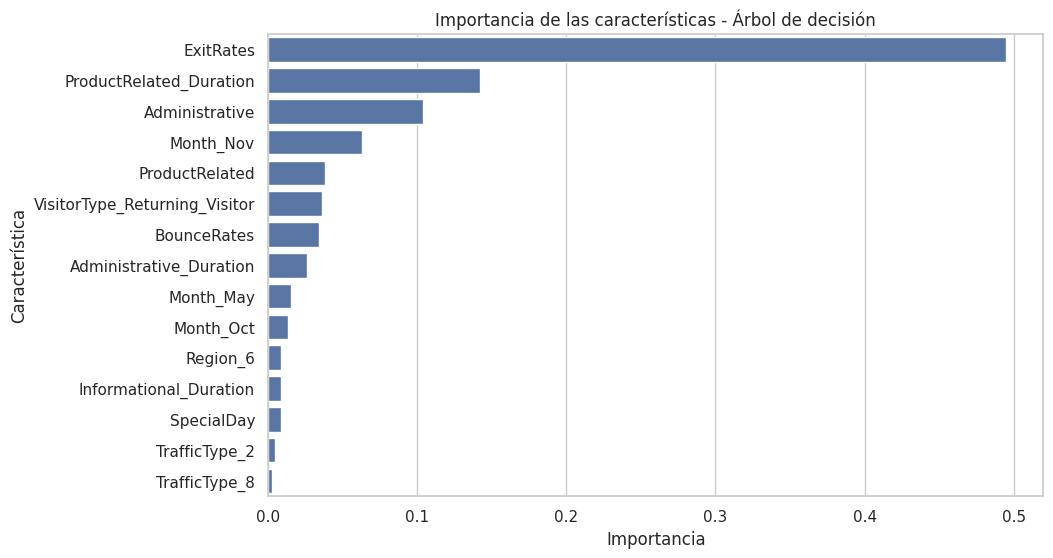

In [19]:
# Importancia de las características
importances = pd.DataFrame({
    'Caracteristica': X_ent.columns,
    'Importancia': np.round(dt.feature_importances_, 4)
})

importances = importances.sort_values(
    'Importancia', ascending=False
)

display(importances.head(20))

# Graficar las 15 más importantes
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importances.head(15),
    x='Importancia',
    y='Caracteristica'
)

plt.title('Importancia de las características - Árbol de decisión')
plt.xlabel('Importancia')
plt.ylabel('Característica')
plt.show()

**Observaciones:**

- Se entrenó un árbol de decisión con una profundidad máxima de **5 niveles**, obteniendo un modelo con **31 hojas**.
- **`ExitRates` fue la característica más importante (49.51 %)**, lo que indica que la tasa de salida tuvo una participación destacada en las decisiones realizadas por el árbol para clasificar las sesiones.
- La segunda característica más importante fue **`ProductRelated_Duration` (14.18 %)**, seguida por **`Administrative` (10.37 %)**. Esto sugiere que el tiempo dedicado a productos y el número de páginas administrativas también aportan información para distinguir las sesiones.
- **`Month_Nov` obtuvo una importancia del 6.31 %**, lo que muestra que la categoría correspondiente a noviembre fue utilizada por el árbol para realizar algunas divisiones.
- Otras características relevantes fueron `ProductRelated` (3.84 %), `VisitorType_Returning_Visitor` (3.61 %) y `BounceRates` (3.38 %).
- Estos resultados reflejan la importancia de las variables dentro del árbol entrenado. No demuestran relaciones de causa y efecto ni garantizan que las mismas características sean las más importantes para otros algoritmos.

In [20]:
# Seleccionar las 10 características más importantes
caracteristicas = importances[
    importances['Importancia'] > 0
]['Caracteristica'].head(10).tolist()

print("Características seleccionadas:")
print(caracteristicas)

# Entrenar con todas las características
arbol_todas = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

arbol_todas.fit(X_ent, y_ent)
pred_todas = arbol_todas.predict(X_val)

# Entrenar con las características seleccionadas
arbol_seleccionadas = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

arbol_seleccionadas.fit(X_ent[caracteristicas], y_ent)
pred_seleccionadas = arbol_seleccionadas.predict(
    X_val[caracteristicas]
)

# Comparar resultados
resultados = pd.DataFrame({
    'Modelo': ['Todas', 'Seleccionadas'],
    'Características': [X_ent.shape[1], len(caracteristicas)],
    'Accuracy': [
        accuracy_score(y_val, pred_todas),
        accuracy_score(y_val, pred_seleccionadas)
    ],
    'Precision': [
        precision_score(y_val, pred_todas, zero_division=0),
        precision_score(y_val, pred_seleccionadas, zero_division=0)
    ],
    'Recall': [
        recall_score(y_val, pred_todas, zero_division=0),
        recall_score(y_val, pred_seleccionadas, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_val, pred_todas, zero_division=0),
        f1_score(y_val, pred_seleccionadas, zero_division=0)
    ]
})

display(resultados.round(4))

Características seleccionadas:
['ExitRates', 'ProductRelated_Duration', 'Administrative', 'Month_Nov', 'ProductRelated', 'VisitorType_Returning_Visitor', 'BounceRates', 'Administrative_Duration', 'Month_May', 'Month_Oct']


,Modelo,Características,Accuracy,Precision,Recall,F1-score
0,Todas,72,0.6899,0.2868,0.6640,0.4006
1,Seleccionadas,10,0.6002,0.2472,0.7638,0.3736


**Observaciones:**

- Se compararon dos árboles de decisión: uno con las **72 características codificadas** y otro con las **10 características de mayor importancia**.
- **El modelo con 72 características obtuvo mejores resultados generales**, alcanzando un accuracy de **68.99 %**, precision de **28.68 %** y F1-score de **40.06 %**.
- **El modelo con 10 características obtuvo un recall superior (76.38 %)**, frente al **66.40 %** del modelo completo. Esto indica que identificó una mayor proporción de las sesiones que terminaron en compra.
- Sin embargo, al reducir las características, la precision disminuyó de **28.68 % a 24.72 %**, mientras que el F1-score pasó de **40.06 % a 37.36 %**.
- Estos resultados muestran que reducir las características mejora la detección de compras, pero también aumenta la proporción de predicciones positivas incorrectas.
- **Por el momento, el modelo con 72 características presenta un mejor equilibrio entre precision y recall**, según su F1-score. La elección definitiva dependerá también de los resultados de los demás clasificadores.

### Selección de características mediante Random Forest

Se utilizará Random Forest para identificar las características más relevantes en la predicción de `Revenue`. A diferencia del árbol de decisión, este algoritmo combina múltiples árboles, lo que permite comparar la importancia obtenida mediante ambos métodos.

In [21]:
from sklearn.ensemble import RandomForestClassifier

# Crear el modelo Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Entrenar con los mismos datos del árbol de decisión
rf.fit(X_ent, y_ent)

print("Número de árboles:", rf.n_estimators)
print("Número de características:", X_ent.shape[1])

Número de árboles: 100
Número de características: 72


,Caracteristica,Importancia
7,ExitRates,0.1931
5,ProductRelated_Duration,0.1688
6,BounceRates,0.1087
0,Administrative,0.1017
4,ProductRelated,0.0817
1,Administrative_Duration,0.0584
17,Month_Nov,0.0508
71,VisitorType_Returning_Visitor,0.0244
60,TrafficType_2,0.0244
69,VisitorType_New_Visitor,0.0209


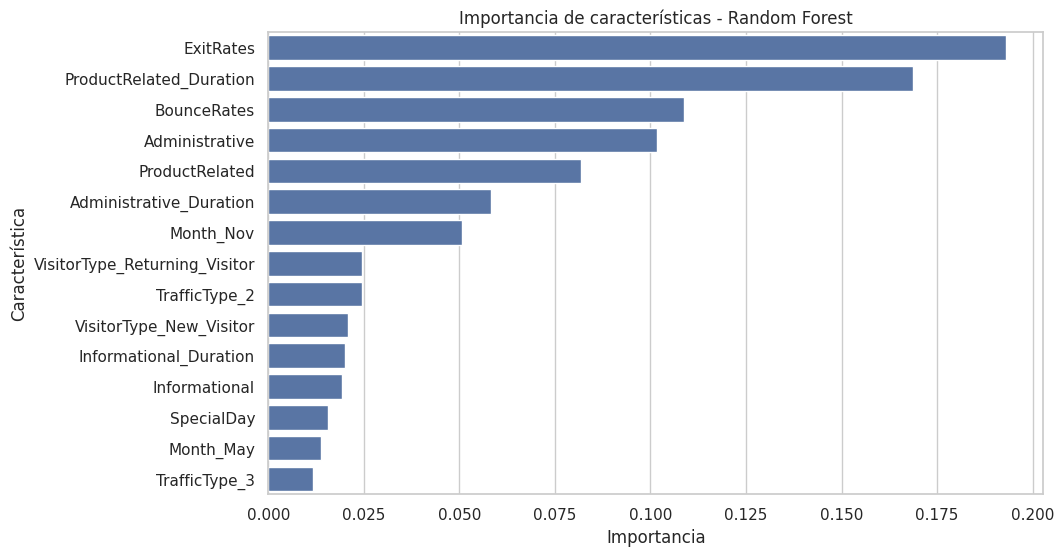

In [22]:
# Importancia de características con Random Forest
importancias_rf = pd.DataFrame({
    'Caracteristica': X_ent.columns,
    'Importancia': np.round(rf.feature_importances_, 4)
})

importancias_rf = importancias_rf.sort_values(
    'Importancia', ascending=False
)

display(importancias_rf.head(20))

# Graficar las 15 más importantes
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias_rf.head(15),
    x='Importancia',
    y='Caracteristica'
)

plt.title('Importancia de características - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Característica')
plt.show()

### Comparación de importancia de características

Se compararán las importancias obtenidas mediante el árbol de decisión y Random Forest para identificar coincidencias y diferencias en las variables utilizadas para predecir `Revenue`.

,Caracteristica,ArbolDecision,RandomForest
7,ExitRates,0.4951,0.1931
5,ProductRelated_Duration,0.1418,0.1688
6,BounceRates,0.0338,0.1087
0,Administrative,0.1037,0.1017
4,ProductRelated,0.0384,0.0817
1,Administrative_Duration,0.0261,0.0584
17,Month_Nov,0.0631,0.0508
71,VisitorType_Returning_Visitor,0.0361,0.0244
60,TrafficType_2,0.0045,0.0244
69,VisitorType_New_Visitor,0.0000,0.0209


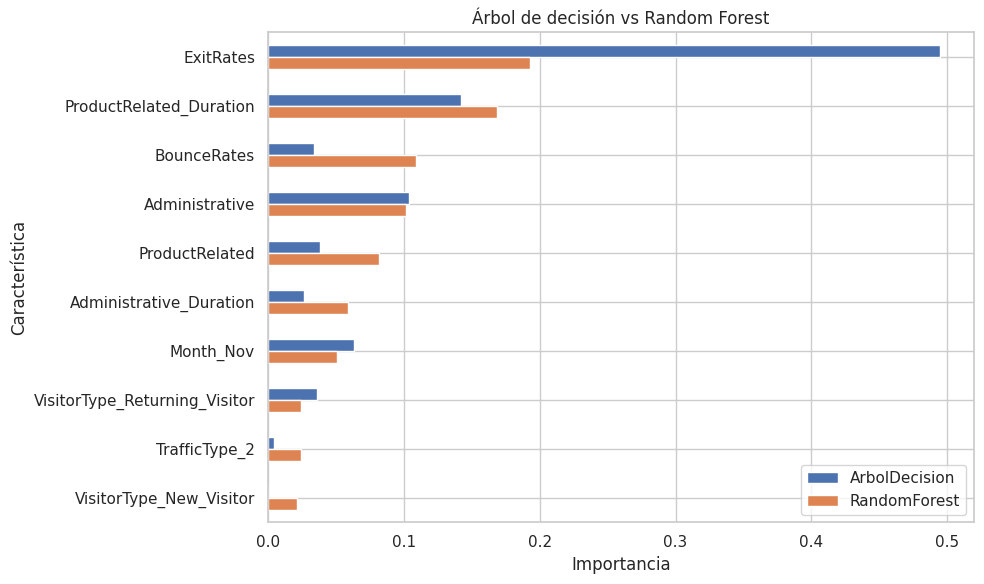

In [24]:
# Comparar importancias de ambos modelos
comparacion_importancias = pd.DataFrame({
    'Caracteristica': X_ent.columns,
    'ArbolDecision': dt.feature_importances_,
    'RandomForest': rf.feature_importances_
})

# Ordenar según la importancia de Random Forest
comparacion_importancias = comparacion_importancias.sort_values(
    'RandomForest', ascending=False
)

display(comparacion_importancias.head(15).round(4))

# Seleccionar las 10 características más importantes de Random Forest
top10 = comparacion_importancias.head(10)

top10.set_index('Caracteristica')[
    ['ArbolDecision', 'RandomForest']
].plot(kind='barh', figsize=(10, 6))

plt.title('Árbol de decisión vs Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Característica')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Observaciones:**

- Se entrenó un modelo Random Forest compuesto por **100 árboles de decisión**, utilizando las 72 características codificadas del conjunto de entrenamiento interno.
- **`ExitRates` presentó la mayor importancia (19.31 %)**, seguida de **`ProductRelated_Duration` (16.88 %)** y **`BounceRates` (10.87 %)**. Esto indica que las tasas de salida y rebote, junto con el tiempo dedicado a páginas de productos, fueron relevantes para las divisiones realizadas por el modelo.
- **`Administrative` (10.17 %) y `ProductRelated` (8.17 %)** también presentaron importancias destacadas, por lo que la cantidad de páginas consultadas aporta información para la clasificación.
- **`Month_Nov` obtuvo una importancia del 5.08 %**, lo que indica que la categoría correspondiente a noviembre fue utilizada por el modelo.
- Las importancias muestran la contribución relativa de las características dentro del Random Forest entrenado. No indican que una variable provoque una compra ni representan directamente probabilidades de compra.

### Evaluación inicial de Random Forest

Se evaluará el desempeño de Random Forest para predecir si una sesión termina en compra, utilizando las mismas sesiones de validación que el árbol de decisión.

In [25]:
# Predecir con Random Forest
pred_rf = rf.predict(X_val)

# Comparar los dos modelos
comparacion_modelos = pd.DataFrame({
    'Modelo': ['Árbol de decisión', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_val, pred_todas),
        accuracy_score(y_val, pred_rf)
    ],
    'Precision': [
        precision_score(y_val, pred_todas),
        precision_score(y_val, pred_rf)
    ],
    'Recall': [
        recall_score(y_val, pred_todas),
        recall_score(y_val, pred_rf)
    ],
    'F1-score': [
        f1_score(y_val, pred_todas),
        f1_score(y_val, pred_rf)
    ]
})

display(comparacion_modelos.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score
0,Árbol de decisión,0.6899,0.2868,0.664,0.4006
1,Random Forest,0.6317,0.2688,0.790,0.4011


**Observaciones:**

- Se comparó el desempeño de un árbol de decisión y Random Forest utilizando las mismas **72 características** y los mismos datos de validación.
- **El árbol de decisión obtuvo mayor accuracy (68.99 %) y precision (28.68 %)**, frente al 63.17 % y 26.88 % de Random Forest. Esto indica que el árbol logró una mayor proporción de predicciones correctas y una mayor precisión al identificar compras.
- **Random Forest obtuvo un recall superior (79.00 %)**, frente al 66.40 % del árbol de decisión. Esto significa que Random Forest identificó una mayor proporción de las sesiones que realmente terminaron en compra.
- **El F1-score fue prácticamente igual en ambos modelos:** 40.06 % para el árbol y 40.11 % para Random Forest. Por lo tanto, no se observa una mejora importante en el equilibrio entre precision y recall.
- **Random Forest resulta más conveniente si se busca detectar la mayor cantidad posible de compras**, mientras que el árbol presenta mejores resultados en accuracy y precision.
- Ambos modelos presentan una precision relativamente baja, por lo que todavía existe margen de mejora.

### Evaluación de variables derivadas mediante Random Forest

Se analizará si las variables creadas mejoran la capacidad de Random Forest para predecir si una sesión termina en compra (`Revenue`).

In [32]:
# Comparar las variables nuevas

# Definir las variables que vamos a probar
nuevas_variables = [
    'PaginasTotales',
    'VisitoInformativas',
    'TiempoPromedioProducto',
    'PorcentajePaginasProducto',
    'TiempoPromedioPagina'
]

# Configuraciones que vamos a comparar
pruebas = {
    'Original': [],
    'Tiempo promedio producto': ['TiempoPromedioProducto'],
    'Porcentaje páginas producto': ['PorcentajePaginasProducto'],
    'Tiempo promedio página': ['TiempoPromedioPagina'],
    'Todas las nuevas': nuevas_variables
}

resultados_nuevas = []

for nombre, columnas in pruebas.items():

    # Crear copias de entrenamiento y validación
    X_ent_prueba = X_ent.copy()
    X_val_prueba = X_val.copy()

    # Incorporar las variables nuevas
    for columna in columnas:
        X_ent_prueba[columna] = df_trabajo.loc[X_ent.index, columna]
        X_val_prueba[columna] = df_trabajo.loc[X_val.index, columna]

    # Entrenar Random Forest
    modelo = RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_ent_prueba, y_ent)

    # Realizar predicciones
    pred = modelo.predict(X_val_prueba)

    # Guardar resultados
    resultados_nuevas.append({
        'Modelo': nombre,
        'Características': X_ent_prueba.shape[1],
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred, zero_division=0),
        'F1-score': f1_score(y_val, pred, zero_division=0)
    })

# Mostrar comparación
comparacion_nuevas = pd.DataFrame(resultados_nuevas)

display(comparacion_nuevas.round(4))

,Modelo,Características,Accuracy,Precision,Recall,F1-score
0,Original,72,0.6317,0.2688,0.7900,0.4011
1,Tiempo promedio producto,73,0.6305,0.2621,0.7533,0.3889
2,Porcentaje páginas producto,73,0.6350,0.2686,0.7769,0.3992
3,Tiempo promedio página,73,0.6272,0.2611,0.7585,0.3884
4,Todas las nuevas,77,0.6358,0.2635,0.7428,0.3890


**Observaciones:**

- Se evaluaron cinco configuraciones de Random Forest utilizando las mismas sesiones de entrenamiento y validación, con el objetivo de comprobar si las variables derivadas mejoraban la predicción de `Revenue`.

- **El modelo original, con 72 características, obtuvo el mejor recall (79.00 %) y F1-score (40.11 %)**, por lo que presentó el mejor desempeño para identificar sesiones con compra entre las configuraciones evaluadas.

- **`PorcentajePaginasProducto` fue la variable derivada con mejores resultados individuales**, alcanzando un accuracy de **63.50 %**, recall de **77.69 %** y F1-score de **39.92 %**. Aunque mejoró ligeramente el accuracy respecto al modelo original, no consiguió superar su F1-score.

- **La configuración con las cinco variables derivadas obtuvo el mayor accuracy (63.58 %)**, pero su recall disminuyó a **74.28 %** y su F1-score a **38.90 %**.

- **`TiempoPromedioPagina` presentó el menor F1-score (38.84 %)**, mientras que `TiempoPromedioProducto` alcanzó un F1-score de **38.89 %**. Ninguna mejoró los resultados del modelo original.

- **Se decidió conservar las 72 características originales para los siguientes experimentos de clasificación**, debido a que las variables derivadas no mostraron mejoras en recall ni F1-score durante la validación.

- Las variables derivadas se mantendrán documentadas como parte de la generación de nuevas características, aunque no se incorporarán al clasificador principal.

##  Preparación para **regresión lineal**

**Objetivo:** predecir `ProductRelated_Duration` en segundos, sin utilizarla como característica de entrada. Tampoco utilizaremos `Revenue`, ya que aquí buscamos estimar tiempo y no usar un resultado futuro de compra. Excluimos inicialmente `PageValues` por precaución.


In [34]:
# Variables que no se utilizarán para predecir la duración
columnas_excluir_regresion = [
    'Revenue',
    'ProductRelated_Duration',
    'PageValues',
    'PaginasTotales',
    'VisitoInformativas',
    'TiempoPromedioProducto',
    'PorcentajePaginasProducto',
    'TiempoPromedioPagina'
]

X_reg = df_trabajo.drop(columns=columnas_excluir_regresion).copy()
y_reg = df_trabajo['ProductRelated_Duration'].copy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

X_train_reg_aux = X_train_reg.copy()
X_test_reg_aux = X_test_reg.copy()
for variable in columnas_onehot:
    # Usar las mismas categorías de entrenamiento en ambos conjuntos.
    categorias = sorted(X_train_reg_aux[variable].astype(str).unique())
    X_train_reg_aux[variable] = pd.Categorical(
        X_train_reg_aux[variable].astype(str), categories=categorias
    )
    X_test_reg_aux[variable] = pd.Categorical(
        X_test_reg_aux[variable].astype(str), categories=categorias
    )
X_train_reg_aux['Weekend'] = X_train_reg_aux['Weekend'].astype(int)
X_test_reg_aux['Weekend'] = X_test_reg_aux['Weekend'].astype(int)

X_train_reg_cod = pd.get_dummies(X_train_reg_aux, columns=columnas_onehot, dtype=int, drop_first=True)
X_test_reg_cod = pd.get_dummies(X_test_reg_aux, columns=columnas_onehot, dtype=int, drop_first=True)
X_test_reg_cod = X_test_reg_cod.reindex(columns=X_train_reg_cod.columns, fill_value=0)

print('X_train_reg:', X_train_reg_cod.shape)
print('X_test_reg:', X_test_reg_cod.shape)
print('y_train_reg:', y_train_reg.shape)

X_train_reg: (9764, 64)
X_test_reg: (2441, 64)
y_train_reg: (9764,)


In [35]:
# Verificar la preparación de los datos para regresión
print("Características de entrenamiento:", X_train_reg_cod.shape[1])
print("Características de prueba:", X_test_reg_cod.shape[1])

print("\nValores faltantes en entrenamiento:",
      X_train_reg_cod.isna().sum().sum())

print("Valores faltantes en prueba:",
      X_test_reg_cod.isna().sum().sum())

print("\nVariable objetivo:")
print(y_train_reg.describe())

Características de entrenamiento: 64
Características de prueba: 64

Valores faltantes en entrenamiento: 0
Valores faltantes en prueba: 0

Variable objetivo:
count     9764.000000
mean      1203.130713
std       1860.223536
min          0.000000
25%        193.591667
50%        612.104167
75%       1475.257292
max      43171.233380
Name: ProductRelated_Duration, dtype: float64


**Observaciones:**

- Se prepararon los datos para estimar `ProductRelated_Duration` mediante regresión lineal.
- El conjunto de entrenamiento contiene **9,764 sesiones y 64 características codificadas**. El conjunto de prueba utiliza las mismas 64 características.
- No se encontraron valores faltantes en las variables predictoras de entrenamiento ni de prueba.
- Se excluyeron `Revenue`, `PageValues`, la variable objetivo y las variables derivadas para mantener una preparación consistente y evitar posibles fugas de información.
- Los datos quedaron preparados para el entrenamiento del modelo de regresión lineal.

### Análisis de la variable objetivo para regresión lineal

,ProductRelated_Duration
count,9764.000000
mean,1203.130713
std,1860.223536
min,0.000000
25%,193.591667
50%,612.104167
75%,1475.257292
90%,2881.519167
95%,4310.659450
99%,8647.498045


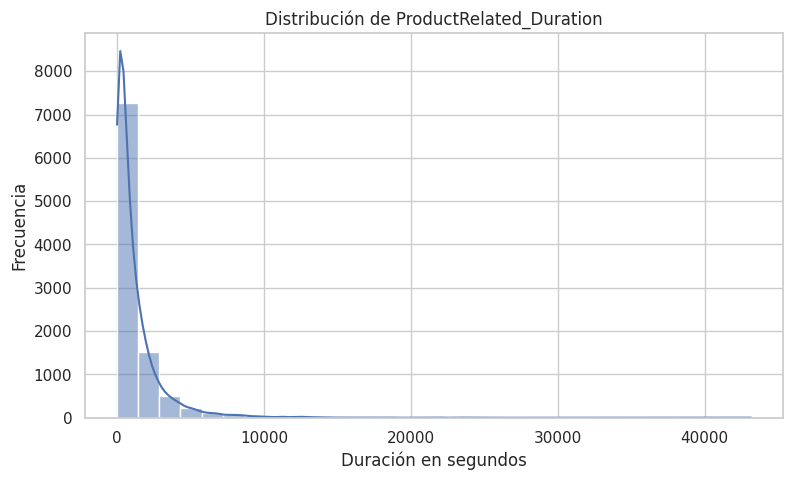

In [36]:
# Estadísticas de la duración de navegación
display(
    y_train_reg.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Histograma
plt.figure(figsize=(9, 5))

sns.histplot(y_train_reg, bins=30, kde=True)

plt.title('Distribución de ProductRelated_Duration')
plt.xlabel('Duración en segundos')
plt.ylabel('Frecuencia')

plt.show()

**Observaciones:**

- **`ProductRelated_Duration` presenta una distribución asimétrica hacia la derecha.** La media fue de **1,203.13 segundos (20.05 minutos)**, mientras que la mediana fue de **612.10 segundos (10.20 minutos)**. Esta diferencia indica que las sesiones con duraciones altas elevan el promedio.

- **El 75 % de las sesiones registró aproximadamente 24.59 minutos o menos** de navegación en páginas de productos, mientras que el 95 % registró aproximadamente **71.84 minutos o menos**.

- **El valor máximo fue de 43,171.23 segundos (aproximadamente 12 horas)**, considerablemente superior a la duración habitual de las sesiones.

- **La desviación estándar fue de 1,860.22 segundos**, superior a la media, lo que indica una dispersión elevada de las duraciones.

- **Se conservarán los valores extremos durante la preparación de los datos**, ya que no se ha demostrado que sean errores. Posteriormente se analizará su influencia en las predicciones y los residuos del modelo de regresión lineal.

## Preparación para **K-Means**



Como K-Means es no supervisado y aquí se busca describir este conjunto de sesiones, se ajusta el escalador con las sesiones que se agruparán. Esta preparación es distinta de la evaluación sobre un conjunto de prueba de un clasificador.

In [38]:
columnas_kmeans = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates'
]

X_kmeans = df_trabajo[columnas_kmeans].copy()
sc_kmeans = StandardScaler()
X_kmeans_scaled = pd.DataFrame(
    sc_kmeans.fit_transform(X_kmeans),
    columns=X_kmeans.columns,
    index=X_kmeans.index
)

print('Datos listos para K-Means:', X_kmeans_scaled.shape)
display(X_kmeans_scaled.head())

Datos listos para K-Means: (12205, 8)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
0,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394
1,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.595451,-0.450137,1.268054
2,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394
3,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.627404,0.654748,2.134590
4,-0.702302,-0.460019,-0.398824,-0.246257,-0.494387,-0.301889,-0.008183,0.184884


### Transformación logarítmica de las características para K-Means

Debido a que algunas variables de navegación presentan distribuciones asimétricas y valores extremos, se preparará una segunda versión de los datos mediante la transformación `log1p`, seguida de la estandarización.

Posteriormente se compararán ambas versiones para evaluar cuál permite obtener agrupamientos más adecuados.

In [39]:
# Transformación logarítmica de las variables
X_kmeans_log = np.log1p(X_kmeans)

# Estandarizar los datos transformados
sc_kmeans_log = StandardScaler()

X_kmeans_log_scaled = pd.DataFrame(
    sc_kmeans_log.fit_transform(X_kmeans_log),
    columns=X_kmeans.columns,
    index=X_kmeans.index
)

print('Datos originales estandarizados:', X_kmeans_scaled.shape)
print('Datos transformados estandarizados:', X_kmeans_log_scaled.shape)

display(X_kmeans_log_scaled.head())

Datos originales estandarizados: (12205, 8)
Datos transformados estandarizados: (12205, 8)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
0,-0.932479,-0.985196,-0.481091,-0.46775,-1.999082,-3.070391,3.922460,3.368043
1,-0.932479,-0.985196,-0.481091,-0.46775,-1.633076,-0.942592,-0.463398,1.313177
2,-0.932479,-0.985196,-0.481091,-0.46775,-1.999082,-3.070391,3.922460,3.368043
3,-0.932479,-0.985196,-0.481091,-0.46775,-1.633076,-2.408111,0.710280,2.156698
4,-0.932479,-0.985196,-0.481091,-0.46775,-0.460236,0.213953,0.012966,0.214558


**Observaciones:**

- Se prepararon dos versiones de los datos para K-Means: una utilizando únicamente `StandardScaler` y otra aplicando `log1p` antes de la estandarización.
- La transformación logarítmica permite comprimir los valores altos de las variables de navegación y reducir su influencia sobre las distancias.
- Se conservaron las mismas ocho características y todas las sesiones, sin eliminar valores extremos.
- Ambas versiones serán utilizadas posteriormente para comparar la calidad de los agrupamientos mediante el método del codo y el coeficiente de silueta.

### Validación de los datos preparados para K-Means

In [45]:
# Validación de los datos preparados para K-Means

# Verificar dimensiones
print("Dimensiones de los datos:")
print("Original:", X_kmeans_scaled.shape)
print("Transformado:", X_kmeans_log_scaled.shape)

# Verificar valores faltantes
print("\nValores faltantes:")
print("Original:", X_kmeans_scaled.isna().sum().sum())
print("Transformado:", X_kmeans_log_scaled.isna().sum().sum())

# Verificar valores infinitos
print("\nValores infinitos:")
print("Original:", np.isinf(X_kmeans_scaled.to_numpy()).sum())
print("Transformado:", np.isinf(X_kmeans_log_scaled.to_numpy()).sum())

# Verificar media y desviación estándar
print("\nEstadísticas de los datos transformados:")

display(pd.DataFrame({
    'Media': X_kmeans_log_scaled.mean(),
    'Desviación estándar': X_kmeans_log_scaled.std(ddof=0)
}).round(3))

# Comprobaciones finales
assert X_kmeans_scaled.shape == X_kmeans_log_scaled.shape

assert not X_kmeans_scaled.isna().any().any()
assert not X_kmeans_log_scaled.isna().any().any()

assert np.isfinite(X_kmeans_scaled.to_numpy()).all()
assert np.isfinite(X_kmeans_log_scaled.to_numpy()).all()

Dimensiones de los datos:
Original: (12205, 8)
Transformado: (12205, 8)

Valores faltantes:
Original: 0
Transformado: 0

Valores infinitos:
Original: 0
Transformado: 0

Estadísticas de los datos transformados:


,Media,Desviación estándar
Administrative,-0.0,1.0
Administrative_Duration,0.0,1.0
Informational,-0.0,1.0
Informational_Duration,0.0,1.0
ProductRelated,0.0,1.0
ProductRelated_Duration,-0.0,1.0
BounceRates,0.0,1.0
ExitRates,-0.0,1.0


**Observaciones:**

- Se verificó la estandarización de las ocho características numéricas utilizadas para K-Means.
- **Todas las variables presentan una media aproximadamente igual a 0 y una desviación estándar igual a 1**, lo que confirma que `StandardScaler` se aplicó correctamente.
- Los valores de `-0.0` corresponden a diferencias muy pequeñas producidas por los cálculos numéricos y no representan errores.
- La estandarización permite que las características tengan escalas comparables, evitando que las variables con valores numéricos más grandes dominen las distancias únicamente por su escala.
- **Los datos transformados quedaron preparados para aplicar K-Means.** Posteriormente se compararán los resultados de la estandarización original y la transformación logarítmica para determinar cuál permite obtener agrupamientos más adecuados.

##  Preparación básica para **Apriori**





In [41]:
# Obtener las medianas
mediana_paginas = df_trabajo['ProductRelated'].median()
mediana_tiempo = df_trabajo['ProductRelated_Duration'].median()
mediana_salida = df_trabajo['ExitRates'].median()

# Crear indicadores booleanos para Apriori
df_apriori = pd.DataFrame({
    'VisitoInformacion': df_trabajo['Informational'] > 0,
    'MuchasPaginasProducto': df_trabajo['ProductRelated'] > mediana_paginas,
    'MuchoTiempoEnProductos': df_trabajo['ProductRelated_Duration'] > mediana_tiempo,
    'SalidaAlta': df_trabajo['ExitRates'] > mediana_salida,
    'FinDeSemana': df_trabajo['Weekend'].astype(bool),
    'VisitanteNuevo': df_trabajo['VisitorType'] == 'New_Visitor',
    'MesNoviembre': df_trabajo['Month'] == 'Nov',
    'Compra': df_trabajo['Revenue'].astype(bool)
}, index=df_trabajo.index)

print('Formato para Apriori:', df_apriori.shape)

display(df_apriori.head())

print('Frecuencia de cada indicador:')
display((df_apriori.mean() * 100).round(2).sort_values(ascending=False))

Formato para Apriori: (12205, 8)


,VisitoInformacion,MuchasPaginasProducto,MuchoTiempoEnProductos,SalidaAlta,FinDeSemana,VisitanteNuevo,MesNoviembre,Compra
0,False,False,False,True,False,False,False,False
1,False,False,False,True,False,False,False,False
2,False,False,False,True,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,True,True,True,False,False,False


Frecuencia de cada indicador:


,0
MuchoTiempoEnProductos,50.00
SalidaAlta,49.65
MuchasPaginasProducto,49.49
MesNoviembre,24.43
FinDeSemana,23.42
VisitoInformacion,21.56
Compra,15.63
VisitanteNuevo,13.87


**Observaciones:**

- Se prepararon **12,205 transacciones con ocho indicadores booleanos** para aplicar Apriori.
- `MuchoTiempoEnProductos` presentó una frecuencia del **50.00 %**, seguido de `SalidaAlta` (49.65 %) y `MuchasPaginasProducto` (49.49 %).
- El indicador `Compra` estuvo presente en el **15.63 %** de las sesiones.
- Se conservó únicamente `Compra` como indicador del resultado, para facilitar la búsqueda de reglas de asociación relacionadas con la compra.
- Los datos se encuentran preparados para aplicar Apriori y analizar soporte, confianza y lift.

## Comprobaciones finales

Validamos que todas las matrices de los modelos tengan tipos adecuados, dimensiones coherentes y ausencia de valores faltantes. no entrenados

In [42]:
assert not X_train_cod.isna().any().any()
assert not X_test_cod.isna().any().any()
assert not X_train_scaled.isna().any().any()
assert not X_test_scaled.isna().any().any()
assert X_train_cod.columns.equals(X_test_cod.columns)
assert X_train_reg_cod.columns.equals(X_test_reg_cod.columns)
assert not X_train_reg_cod.isna().any().any()
assert not X_test_reg_cod.isna().any().any()
assert not X_kmeans_scaled.isna().any().any()
assert df_apriori.dtypes.eq(bool).all()

print('Verificación completada.')
print('Clasificación:', X_train_cod.shape, X_test_cod.shape)
print('Regresión:', X_train_reg_cod.shape, X_test_reg_cod.shape)
print('K-Means:', X_kmeans_scaled.shape)
print('Apriori:', df_apriori.shape)

Verificación completada.
Clasificación: (9764, 72) (2441, 72)
Regresión: (9764, 64) (2441, 64)
K-Means: (12205, 8)
Apriori: (12205, 8)


## Guardar el dataset preparado


**Cambiar el lugar donde lo quiran guardar :)**


In [43]:
carpeta_salida = Path('/content/drive/MyDrive/mineriaDatos')
if not carpeta_salida.exists():
    carpeta_salida = Path('.')

nombre_salida = ('online_shoppers_sin_duplicados.csv' if ELIMINAR_DUPLICADOS
                 else 'online_shoppers_con_duplicados.csv')
archivo_salida = carpeta_salida / nombre_salida
df_trabajo.to_csv(archivo_salida, index=False)
print('Dataset de trabajo guardado en:', archivo_salida)
print('Dimensiones:', df_trabajo.shape)

Dataset de trabajo guardado en: /content/drive/MyDrive/mineriaDatos/online_shoppers_sin_duplicados.csv
Dimensiones: (12205, 23)
